# Model Evaluation

This notebook evaluates a trained fraud model using precision, recall, F1-score, confusion matrix, and ROC/AUC metrics.


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().resolve()
if not (project_root / "data" / "processed").exists():
    project_root = project_root.parent

df = pd.read_csv(project_root / "data" / "processed" / "fraud_sampled.csv")
print(df.head())
print(f"Rows: {len(df)}")
print(df["isFraud"].value_counts(normalize=True).to_dict())


   step      type     amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0    15   PAYMENT   14183.02  C1511752447      424164.19       409981.17   
1    13   CASH_IN  134116.02   C624343034    24950988.41     25085104.43   
2   323  CASH_OUT  264977.25   C926806709       20303.00            0.00   
3   349   PAYMENT   16723.10   C543711584       20373.00         3649.90   
4   369  CASH_OUT  216305.21  C1790143581           0.00            0.00   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979774744            0.00            0.00        0               0  
1  C1113941243       608933.74       474817.72        0               0  
2  C1224322366       991497.14      1256474.39        0               0  
3  M2102407654            0.00            0.00        0               0  
4  C1323576474      3180972.31      3397277.52        0               0  
Rows: 172473
{0: 0.9523809523809523, 1: 0.047619047619047616}


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
)

feature_columns = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "type"]
X = pd.get_dummies(df[feature_columns], columns=["type"], drop_first=True)
y = df["isFraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
model.fit(X_train, y_train)
probs = model.predict_proba(X_test)[:, 1]
preds = model.predict(X_test)

print(classification_report(y_test, preds, target_names=["Non-Fraud", "Fraud"]))
print(confusion_matrix(y_test, preds))
print(f"ROC AUC: {roc_auc_score(y_test, probs):.4f}")
print(f"Average Precision: {average_precision_score(y_test, probs):.4f}")


              precision    recall  f1-score   support

   Non-Fraud       1.00      0.95      0.97     32852
       Fraud       0.47      0.92      0.63      1643

    accuracy                           0.95     34495
   macro avg       0.74      0.94      0.80     34495
weighted avg       0.97      0.95      0.96     34495

[[31175  1677]
 [  126  1517]]
ROC AUC: 0.9879
Average Precision: 0.8784


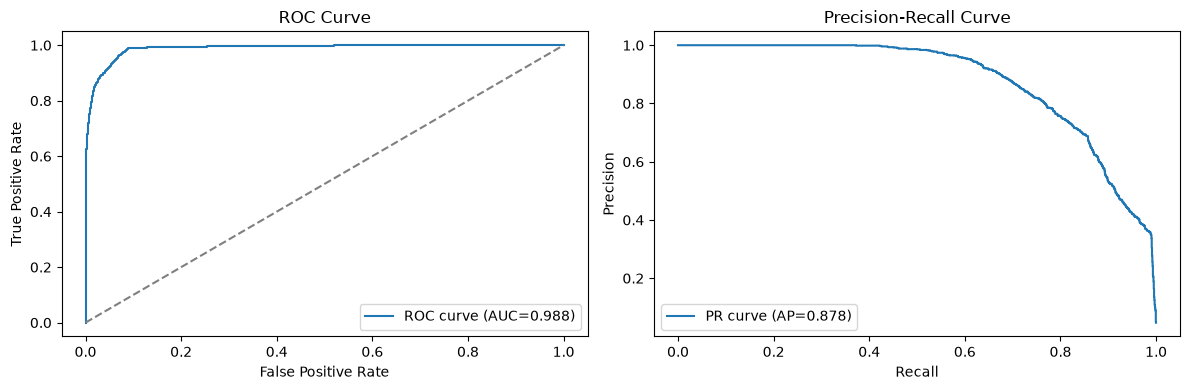

In [4]:
fpr, tpr, _ = roc_curve(y_test, probs)
precision, recall, _ = precision_recall_curve(y_test, probs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(fpr, tpr, label=f"ROC curve (AUC={roc_auc_score(y_test, probs):.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

axes[1].plot(recall, precision, label=f"PR curve (AP={average_precision_score(y_test, probs):.3f})")
axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
plt.tight_layout()
plt.show()
